In [1]:
using Flux
using CUDA, cuDNN
using StatsPlots
using Plots;
default(fontfamily="Computer Modern", framestyle=:box) # LaTex-style
using Random
using LaTeXStrings
using Logging;
using ProgressMeter
using StatsBase
using LinearAlgebra
using ParameterSchedulers
using LoggingExtras
# using MosaicViews
# using NPZ
# using Images

In [2]:
begin
    # Define the device selector based on availability
    const device = CUDA.functional() ? gpu : cpu

    if CUDA.functional()
        @info "🚀 Functional GPU detected! Setting device to CUDA."
    else
        @warn "💻 No GPU found. Falling back to host CPU."
    end

    CUDA.allowscalar(false)  # recommended
end

[ Info: 🚀 Functional GPU detected! Setting device to CUDA.


One dimensional convolution expects data of dimension $748 \times 1\times B$. We introduce this dummy dimension to the data.

In [3]:
include("./utils.jl")
include("./io_utils.jl")
batch_size = 50
mnist_binary_loader, mnist_binary_test, mnist_binary_valid = load_binary_mnist_data(batch_size; tensor_shape=(28^2, 1, :))

mnist_binary_test_loader = Flux.DataLoader((mnist_binary_test,), batchsize=batch_size)
mnist_binary_valid_loader = Flux.DataLoader((mnist_binary_valid,), batchsize=batch_size);
# mnist_binary_loader, mnist_binary_test, mnist_binary_valid = load_binary_mnist_data(batch_size; tensor = false)

In [4]:
# global_logger(cudnn_filter);

In [5]:
# mnist_binary_train = mnist_binary_loader.data[1]
# mnist_binary_loader = Flux.DataLoader((reshape(mnist_binary_train, 28^2, 1, :), ), batchsize = batch_size, shuffle=true)
# mnist_binary_test_loader = Flux.DataLoader((reshape(mnist_binary_test, 28^2, 1, :),), batchsize = batch_size)
# mnist_binary_valid_loader = Flux.DataLoader((reshape(mnist_binary_valid, 28^2, 1, :), ), batchsize = batch_size);


In [6]:
begin

    struct CausalConv1D2{C<:Conv}
        conv::C
        left_pad::Int
        res_con::Bool
    end

    # Register the layer with Flux to automatically track internal weights
    Flux.@layer CausalConv1D2 trainable = (conv,)

    function CausalConv1D2(kernel_size::Int, ch::Pair{<:Int,<:Int}, σ=identity; res_con=false, dilation=1, bias=true)
        # 1. Total causal padding needed on the left
        left_pad = (kernel_size - 1) * dilation

        # 2. THE GPU TRICK: We apply the full padding symmetrically to BOTH sides.
        # This keeps the convolution operations locked inside highly optimized cuDNN loops.
        standard_conv = Conv((kernel_size,), ch, σ; dilation=dilation, bias=bias, pad=(left_pad, 0))
        res_con = res_con && (ch[1] == ch[2]) ## residual connection only allowed if the in and out channel is the same
        return CausalConv1D2(standard_conv, left_pad, res_con)
    end

    function (m::CausalConv1D2)(x::AbstractArray)
        # x layout: (Sequence_Length, Channels, Batch)

        # 3. Perform the fast, symmetrically-padded convolution pass
        out_padded = m.conv(x)

        # 4. TRIM THE FUTURE: By slicing the array from index 1 up to (end - left_pad), 
        # we effectively shift the padding entirely to the left side. 
        # Slicing a CuArray on the GPU is virtually free and generates zero allocations.
        # return out_padded[1:(end-m.left_pad), :, :]
        if m.res_con
            out_padded = out_padded + x
        end
        return out_padded
    end
end

In [7]:
begin

    struct CausalConv1D{C<:Conv}
        conv::C
        res_con::Bool
    end


    Flux.@layer CausalConv1D trainable = (conv,)


    function CausalConv1D(kernel_size::Int, ch::Pair{<:Integer,<:Integer}, act=identity; res_con=false, dilation=1, bias=true)
        # Internally initialize a standard Flux Conv layer without internal padding
        standard_conv = Conv((kernel_size,), ch, act; dilation=dilation, bias=bias, pad=0)

        res_con = res_con && (ch[1] == ch[2]) ## residual connection only allowed if the in and out channel is the same
        return CausalConv1D(standard_conv, res_con)
    end

    function (m::CausalConv1D)(x::AbstractArray)
        # Layout assumed: (Sequence_Length, Channels, Batch)

        # Extract kernel size and dilation from the internal convolution layer
        k = size(m.conv.weight, 1)
        d = m.conv.dilation[1]

        # Calculate required causal left-padding
        left_pad = (k - 1) * d

        # Front-pad with zeros safely across the sequence dimension (Dimension 1)
        # pad_zeros takes a tuple of (left, right) adjustments per dimension
        x_padded = Flux.pad_zeros(x, (left_pad, 0); dims=1)

        # zero_matrix = similar(x, eltype(x), left_pad, size(xs)[(end-1):end]...) .= 0
        # cat(zero_matrix, xs, dims=1)
        # x_padded = cat(zero_matrix, x, dims=1)
        out = m.conv(x_padded)

        # Pass the left-padded data directly through the standard convolution layer
        if m.res_con
            return out + x
        else
            return out
        end
    end
end

In [8]:
begin


    struct PixelCNN1D{T<:Chain}
        d::Int ## number of input; or input dimension
        net::T ## trainable network
        kernel_size::Int
        dilation::Bool
        add_loc::Bool
        res_con::Bool
    end



    Flux.@layer PixelCNN1D trainable = (net,)

    function PixelCNN1D(d::Int=28^2, num_layers=5, kernel_size::Int=3, nc::Int=32; res_con=false, add_loc=false, dilation=false, act=relu, init=Flux.glorot_uniform, built_in_padding=false)
        net = []
        for l in 1:num_layers
            dil = dilation ? 2^(l-1) : 1 ## exponentially expanding dilation
            dil = min(d, dil)
            in_nc = l == 1 ? (add_loc ? 2 : 1) : nc
            res_connection = l == 1 ? false : res_con
            if built_in_padding
                push!(net, CausalConv1D2(kernel_size, in_nc => nc, act; res_con=res_connection, dilation=dil, bias=true))
            else
                push!(net, CausalConv1D(kernel_size, in_nc => nc, act; res_con=res_connection, dilation=dil, bias=true))
            end
        end
        if built_in_padding
            push!(net, CausalConv1D2(1, nc => 1; res_con=false, bias=true))
        else
            push!(net, CausalConv1D(1, nc => 1; res_con=false, bias=true))
        end
        net = Chain(net...)
        return PixelCNN1D(d, net, kernel_size, dilation, add_loc, res_con)
    end

    function (m::PixelCNN1D)(xs)
        if m.add_loc
            loc = Flux.ignore_derivatives() do
                location_feature(xs)
            end
            xs = cat(xs, loc, dims=2)
        end
        xs = Flux.pad_zeros(xs, (1, 0), dims=1)[1:(end-1), :, :]
        return m.net(xs)
    end

end

In [9]:
begin

    struct ResWaveNetBlock{T<:Union{CausalConv1D,CausalConv1D2},Y<:Conv}
        causal_con::T
        res_con::Y
    end

    Flux.@layer ResWaveNetBlock trainable = (causal_con, res_con)


    function ResWaveNetBlock(kernel_size::Int=2, dilation::Int=1, ch::Int=32)
        causal_con = CausalConv1D(kernel_size, ch => 2 * ch, identity; res_con=false, dilation=dilation, bias=true)
        res_con = Conv((1,), ch => ch, identity)
        ResWaveNetBlock(causal_con, res_con)
    end


    function (m::ResWaveNetBlock)(xs)
        output = m.causal_con(xs)
        out_f, out_g = Flux.chunk(output, 2, dims=2)
        output = tanh.(out_f) .* σ(out_g)
        output = m.res_con(output)
        return xs + output, output
    end
end

In [10]:
begin

    struct WaveNet{T<:CausalConv1D,Y<:Chain,K<:Union{Chain,CausalConv1D}}
        d::Int ## number of input; or input dimension
        input_layer::T
        res_blocks::Y
        output_layer::K
        # kernel_size::Int
        # dilation::Bool
        add_loc::Bool
        forward_mode::Symbol ## forward mode: :chain or :skip
    end

    Flux.@layer WaveNet trainable = (input_layer, res_blocks, output_layer)

    function WaveNet(d::Int=28^2, num_layers=5, kernel_size::Int=2, nc::Int=32; forward_mode=:chain, add_loc=false, dilation=false, act=relu, init=Flux.glorot_uniform)
        input_layer = CausalConv1D(kernel_size, (add_loc ? 2 : 1) => nc, identity; res_con=false, dilation=1, bias=true)   ## causal mask A
        res_blocks = []
        cap_l = floor(Int, log(kernel_size, 512))
        dils = [2^(l-1) for l in 1:(cap_l+1)]
        for l in 1:num_layers
            dil = dilation ? dils[((l-1)%(length(dils))+1)] : 1 ## exponentially expanding dilation and cycle back 1,2,…,512,1,2,3...
            dil = min(dil, 512)
            push!(res_blocks, ResWaveNetBlock(kernel_size, dil, nc))
        end

        if forward_mode == :chain
            output_layer = CausalConv1D(1, nc => 1)
        else
            out1 = CausalConv1D(1, nc => nc, act)
            out2 = CausalConv1D(1, nc => 1, identity)
            output_layer = Chain(out1, out2)
        end
        WaveNet(d, input_layer, Chain(res_blocks...), output_layer, add_loc, forward_mode)
    end


    function (m::WaveNet)(xs)
        if m.add_loc
            loc = Flux.ignore_derivatives() do
                location_feature(xs)
            end
            xs = cat(xs, loc, dims=2)
        end
        xs = Flux.pad_zeros(xs, (1, 0), dims=1)[1:(end-1), :, :]
        hs = m.input_layer(xs)

        out1, out2 = m.res_blocks[1](hs)
        total_skip = out2
        for layer in m.res_blocks[2:end]
            out1, out2 = layer(out1)
            total_skip += out2
        end

        if m.forward_mode == :chain
            output = m.output_layer(out1)
        else
            total_skip = relu(total_skip)
            output = m.output_layer(total_skip)
        end

        return output
    end



end

In [11]:
begin

    function location_feature(xs)
        d = size(xs)[1]
        batch_size = size(xs)[end]
        if eltype(xs) == Bool
            xs = float32.(xs)
        end
        loc_mat = similar(xs)
        loc_mat[:, :, 1:end] .= range(0.f0, 1.f0, d)
        return loc_mat
    end

    function add_location(xs)
        # d = size(xs)[1]
        # batch_size = size(xs)[end]
        # if eltype(xs) == Bool
        #     xs = float32.(xs)
        # end
        # loc_mat = similar(xs)
        # loc_mat[:, :, 1:end] .= range(0.f0, 1.f0, d)
        loc_mat = location_feature(xs)
        cat(xs, loc_mat, dims=2)
    end

    function logpdf(model::Union{PixelCNN1D,WaveNet}, xs::AbstractArray; reduction=mean)
        xs_preds = model(xs)
        logL = -Flux.logitbinarycrossentropy(xs_preds[:, 1, :], xs[:, 1, :]; agg=identity)
        logL = sum(logL, dims=1)
        logL |> reduction
    end


    function logpdf(model::Union{PixelCNN1D,WaveNet}, data_loader::Flux.DataLoader; reduction=mean)
        logLiks = []
        for (xs,) in data_loader
            xs = xs |> device
            # if model.add_loc
            #     xs = add_location(xs)
            # end
            # xs_preds = model(xs)
            # logL = -Flux.logitbinarycrossentropy(xs_preds[:, 1, :], xs[:, 1, :]; agg=identity)
            # logL = sum(logL, dims=1)[:]
            logL = logpdf(model, xs; reduction=identity)[:]
            append!(logLiks, logL)
        end
        return logLiks |> reduction
    end

    function sample(model::Union{PixelCNN1D,WaveNet}, n=1)
        xs = Array{Bool}(undef, model.d, 1, n) |> device
        # if model.add_loc
        #     xs = add_location(xs)
        # end
        for d in 1:model.d
            ps = σ(model(xs)[d, :, :])
            xs[d, 1, :] = rand_like(ps)[:] .< ps[:]
        end
        return xs[:, 1, :]
    end


    function fit!(model::Union{PixelCNN1D,WaveNet}, data_loader, optim=Adam(), max_epochs=10; verbose=true, every_epoch=10, learning_rate_decay=true, validation_data_loader=nothing, patience=Inf)
        total_d = model.d
        initial_lr = optim.eta ## initial learning rate
        if learning_rate_decay
            total_batches_per_epoch = length(data_loader)
            total_steps = max_epochs * total_batches_per_epoch
            # 1. Calculate your steps based on your data loop
            warmup_steps = Int(ceil(0.1 * total_steps))   # e.g., 10% of your training loop
            decay_steps = total_steps - warmup_steps  # The remaining steps in your training loop
            # 2. Define the two phases
            ss = WarmupLinear(1e-6, Float64(initial_lr), warmup_steps, total_steps, CosAnneal(Float64(initial_lr), 1e-6, decay_steps))

            # 3. Combine them chronologically into a single schedule
            schedule = ParameterSchedulers.Stateful(ss)
        end
        opt = Flux.setup(optim, model)
        losses = []
        validation_check = false
        best_model = deepcopy(model |> cpu)
        if !isnothing(validation_data_loader)
            # Trackers for early stopping
            validation_check = true
            best_val_loss = Inf
            # To save a checkpoint of the best model
            epochs_no_improve = 0
        end

        @showprogress for epoch in 1:max_epochs
            for (xs,) in data_loader
                batch_size = size(xs)[end]
                xs = xs |> device
                li, gs = Flux.withgradient(model) do m
                    -logpdf(m, xs)
                end
                Flux.update!(opt, model, gs[1])
                push!(losses, li)

                if learning_rate_decay
                    next_lr = ParameterSchedulers.next!(schedule)
                    Flux.adjust!(opt, next_lr)
                end
            end

            if validation_check
                current_val_loss = -logpdf(model, validation_data_loader)

                # --- EARLY STOPPING LOGIC ---
                if current_val_loss < best_val_loss
                    # New best found! Reset patience tracker and save parameters
                    best_val_loss = current_val_loss
                    best_model = deepcopy(model |> cpu) # Save snapshot
                    epochs_no_improve = 0
                else
                    epochs_no_improve += 1
                end

                # Check if patience has run out
                if epochs_no_improve >= patience
                    # initial_lr *= 0.5
                    # Flux.adjust!(opt, eta=initial_lr)
                    @info "🛑 Early stopping triggered! No improvement for $patience epochs."
                    epochs_no_improve = 0
                    break
                end
            end

            if verbose && (epoch % every_epoch) == 1
                @info "Epoch $(epoch); Loss = $(round(losses[end]; digits=4))"
            end
        end

        return losses, best_model
    end
end

fit! (generic function with 3 methods)

In [12]:
begin
    ks = 2
    nc = 32
    n_layers = 9
    Random.seed!(123)
    # ks = 2
    # nc = 32
    # n_layers = 10
    pix_net_no_dil = PixelCNN1D(28^2, n_layers, ks, nc; dilation=false, built_in_padding=true) |> device
    losses_no_dil, _ = fit!(pix_net_no_dil, mnist_binary_loader, Adam(), 5; verbose=true, every_epoch=2, learning_rate_decay=true, validation_data_loader=nothing)

    # pix_net_no_dil(randn(28^2,1,1))

    # xs, = mnist_binary_loader |> first

    # pix_net_no_dil(xs |> device)
end

[ Info: Epoch 1; Loss = 170.5523
Progress:  40%|████████████████▍                        |  ETA: 0:02:35[ Info: Epoch 3; Loss = 177.0089
Progress:  80%|████████████████████████████████▊        |  ETA: 0:00:28[ Info: Epoch 5; Loss = 176.5986
Progress: 100%|█████████████████████████████████████████| Time: 0:01:58


(Any[544.03937f0, 542.17365f0, 542.1587f0, 542.1347f0, 542.1315f0, 542.08966f0, 542.091f0, 542.07556f0, 542.0066f0, 541.939f0  …  180.27768f0, 171.49652f0, 172.67801f0, 175.73087f0, 171.07497f0, 174.96364f0, 173.237f0, 177.0916f0, 173.14441f0, 176.59863f0], PixelCNN1D{Chain{Tuple{CausalConv1D2{Conv{1, 2, typeof(relu), Array{Float32, 3}, Vector{Float32}}}, CausalConv1D2{Conv{1, 2, typeof(relu), Array{Float32, 3}, Vector{Float32}}}, CausalConv1D2{Conv{1, 2, typeof(relu), Array{Float32, 3}, Vector{Float32}}}, CausalConv1D2{Conv{1, 2, typeof(relu), Array{Float32, 3}, Vector{Float32}}}, CausalConv1D2{Conv{1, 2, typeof(relu), Array{Float32, 3}, Vector{Float32}}}, CausalConv1D2{Conv{1, 2, typeof(relu), Array{Float32, 3}, Vector{Float32}}}, CausalConv1D2{Conv{1, 2, typeof(relu), Array{Float32, 3}, Vector{Float32}}}, CausalConv1D2{Conv{1, 2, typeof(relu), Array{Float32, 3}, Vector{Float32}}}, CausalConv1D2{Conv{1, 2, typeof(relu), Array{Float32, 3}, Vector{Float32}}}, CausalConv1D2{Conv{1, 2, t

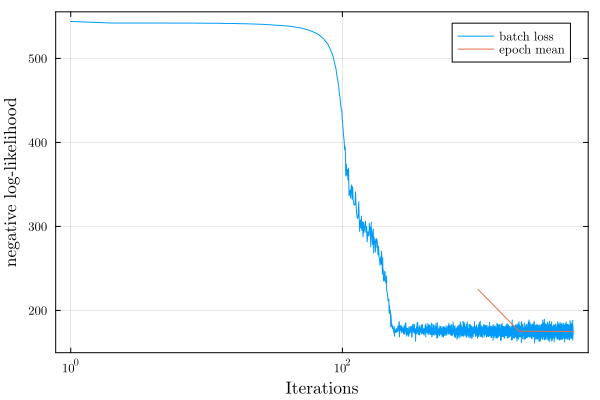

In [13]:
plot_loss(losses_no_dil, length(mnist_binary_loader))

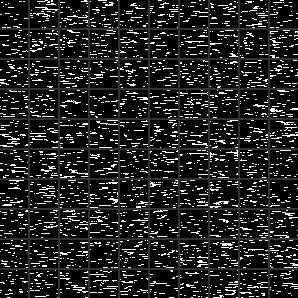

In [14]:
vec2imgs(sample(pix_net_no_dil, 100); nrows=10)

In [15]:
logpdf(pix_net_no_dil, mnist_binary_test_loader; reduction=mean)

-174.9412f0

In [16]:
begin
    Random.seed!(123)

    pix_net_dil = PixelCNN1D(28^2, n_layers, ks, nc; dilation=true, built_in_padding=false) |> device
    losses_dil, _ = fit!(pix_net_dil, mnist_binary_loader, Adam(), 8; verbose=true, every_epoch=2, learning_rate_decay=true, validation_data_loader=nothing)
end;

[ Info: Epoch 1; Loss = 94.6819
Progress:  25%|██████████▎                              |  ETA: 0:01:01[ Info: Epoch 3; Loss = 91.969
Progress:  50%|████████████████████▌                    |  ETA: 0:00:33[ Info: Epoch 5; Loss = 92.7985
Progress:  75%|██████████████████████████████▊          |  ETA: 0:00:16[ Info: Epoch 7; Loss = 97.8176
Progress: 100%|█████████████████████████████████████████| Time: 0:00:59


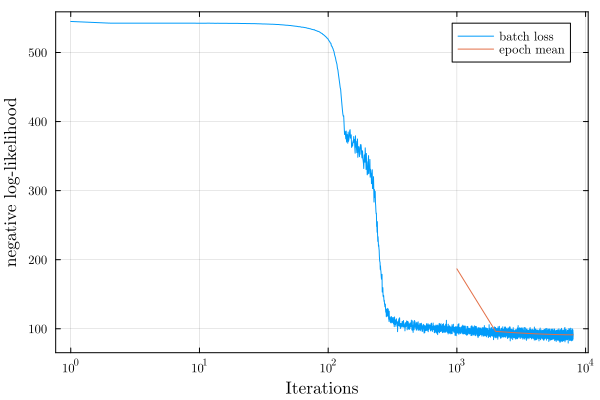

In [17]:
plot_loss(losses_dil, length(mnist_binary_loader))

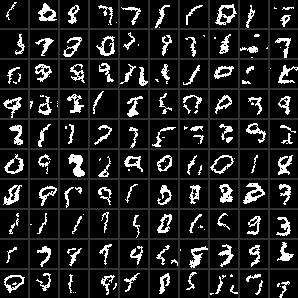

In [18]:
vec2imgs(sample(pix_net_dil, 100); nrows=10)

In [19]:
logpdf(pix_net_dil, mnist_binary_test_loader; reduction=mean)

-90.62777f0

In [20]:
begin
    Random.seed!(123)

    pix_net_dil_loc_res = PixelCNN1D(28^2, n_layers, ks, nc; res_con=true, dilation=true, add_loc=true, built_in_padding=true) |> device
    losses_dil_loc_res, _ = fit!(pix_net_dil_loc_res, mnist_binary_loader, Adam(1e-3), 10; verbose=true, every_epoch=2, learning_rate_decay=false, validation_data_loader=nothing)
end;

[ Info: Epoch 1; Loss = 95.7643
Progress:  20%|████████▎                                |  ETA: 0:01:11[ Info: Epoch 3; Loss = 93.9658
Progress:  40%|████████████████▍                        |  ETA: 0:00:44[ Info: Epoch 5; Loss = 94.205
Progress:  60%|████████████████████████▋                |  ETA: 0:00:27[ Info: Epoch 7; Loss = 99.8328
Progress:  80%|████████████████████████████████▊        |  ETA: 0:00:13[ Info: Epoch 9; Loss = 88.9696
Progress: 100%|█████████████████████████████████████████| Time: 0:01:04


In [21]:
begin
    Random.seed!(123)

    pix_net_dil_loc = PixelCNN1D(28^2, n_layers, ks, nc; dilation=true, add_loc=true) |> device
    losses_dil_loc, _ = fit!(pix_net_dil_loc, mnist_binary_loader, Adam(), 10; verbose=true, every_epoch=2, learning_rate_decay=false, validation_data_loader=nothing)
end;

[ Info: Epoch 1; Loss = 92.4299
Progress:  20%|████████▎                                |  ETA: 0:00:58[ Info: Epoch 3; Loss = 91.0996
Progress:  40%|████████████████▍                        |  ETA: 0:00:42[ Info: Epoch 5; Loss = 92.2097
Progress:  60%|████████████████████████▋                |  ETA: 0:00:28[ Info: Epoch 7; Loss = 97.0976
Progress:  80%|████████████████████████████████▊        |  ETA: 0:00:14[ Info: Epoch 9; Loss = 86.9145
Progress: 100%|█████████████████████████████████████████| Time: 0:01:08


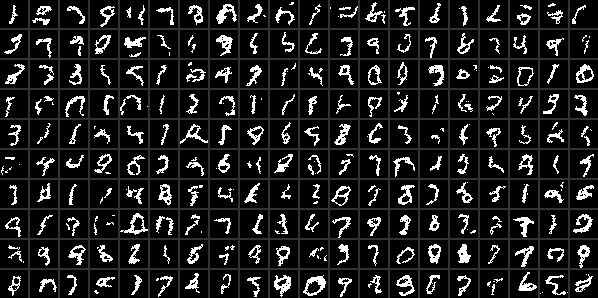

In [22]:
vec2imgs(sample(pix_net_dil_loc, 200); nrows=10)

In [23]:
logpdf(pix_net_dil_loc, mnist_binary_test_loader; reduction=mean)

-88.640915f0

In [24]:
begin

    Random.seed!(123)
    wave_net_dil = WaveNet(28^2, n_layers, ks, nc; add_loc=false, dilation=true) |> device
    losses_dil_wn, _ = fit!(wave_net_dil, mnist_binary_loader, Adam(), 10; verbose=true, every_epoch=2, learning_rate_decay=false, validation_data_loader=nothing)
end

[ Info: Epoch 1; Loss = 96.9187
Progress:  20%|████████▎                                |  ETA: 0:03:31[ Info: Epoch 3; Loss = 87.5963
Progress:  40%|████████████████▍                        |  ETA: 0:01:59[ Info: Epoch 5; Loss = 88.7476
Progress:  60%|████████████████████████▋                |  ETA: 0:01:11[ Info: Epoch 7; Loss = 90.4419
Progress:  80%|████████████████████████████████▊        |  ETA: 0:00:33[ Info: Epoch 9; Loss = 84.4078
Progress: 100%|█████████████████████████████████████████| Time: 0:02:40


(Any[563.8193f0, 510.91058f0, 456.2645f0, 414.4933f0, 361.79892f0, 324.21188f0, 292.29865f0, 268.92163f0, 231.76778f0, 215.19687f0  …  89.56086f0, 89.56971f0, 88.178474f0, 83.60538f0, 88.72207f0, 93.023544f0, 89.037636f0, 87.84109f0, 86.50373f0, 80.910355f0], WaveNet{CausalConv1D{Conv{1, 2, typeof(identity), Array{Float32, 3}, Vector{Float32}}}, Chain{NTuple{9, ResWaveNetBlock{CausalConv1D{Conv{1, 2, typeof(identity), Array{Float32, 3}, Vector{Float32}}}, Conv{1, 2, typeof(identity), Array{Float32, 3}, Vector{Float32}}}}}, CausalConv1D{Conv{1, 2, typeof(identity), Array{Float32, 3}, Vector{Float32}}}}(784, CausalConv1D{Conv{1, 2, typeof(identity), Array{Float32, 3}, Vector{Float32}}}(Conv((2,), 1 => 32), false), Chain(ResWaveNetBlock{CausalConv1D{Conv{1, 2, typeof(identity), Array{Float32, 3}, Vector{Float32}}}, Conv{1, 2, typeof(identity), Array{Float32, 3}, Vector{Float32}}}(CausalConv1D{Conv{1, 2, typeof(identity), Array{Float32, 3}, Vector{Float32}}}(Conv((2,), 32 => 64), false), C

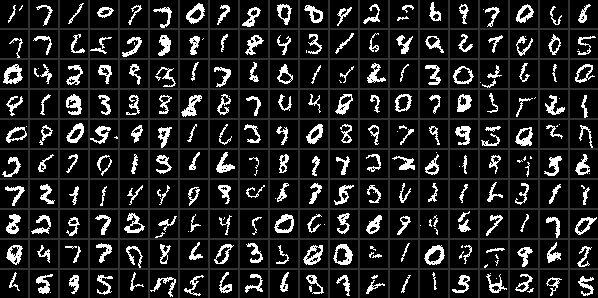

In [25]:
vec2imgs(sample(wave_net_dil, 200); nrows=10)

In [26]:
logpdf(wave_net_dil, mnist_binary_test_loader)

-85.15157f0

In [27]:
begin
    Random.seed!(123)
    wave_net_dil_loc = WaveNet(28^2, n_layers, ks, nc; add_loc=true, dilation=true) |> device
    losses_dil_loc_wn, _ = fit!(wave_net_dil_loc, mnist_binary_loader, Adam(), 10; verbose=true, every_epoch=2, learning_rate_decay=false, validation_data_loader=nothing)
end

[ Info: Epoch 1; Loss = 96.3311
Progress:  20%|████████▎                                |  ETA: 0:01:51

[ Info: Epoch 3; Loss = 86.3576
Progress:  40%|████████████████▍                        |  ETA: 0:01:24[ Info: Epoch 5; Loss = 88.0666
Progress:  60%|████████████████████████▋                |  ETA: 0:00:56[ Info: Epoch 7; Loss = 89.5544
Progress:  80%|████████████████████████████████▊        |  ETA: 0:00:28[ Info: Epoch 9; Loss = 84.1184
Progress: 100%|█████████████████████████████████████████| Time: 0:02:18


(Any[584.4171f0, 472.151f0, 388.18082f0, 360.8555f0, 319.0232f0, 309.75897f0, 314.03326f0, 309.9972f0, 271.92822f0, 252.42181f0  …  88.61428f0, 88.815994f0, 87.61211f0, 82.77841f0, 88.20751f0, 92.199646f0, 87.80036f0, 86.930176f0, 86.02871f0, 80.45882f0], WaveNet{CausalConv1D{Conv{1, 2, typeof(identity), Array{Float32, 3}, Vector{Float32}}}, Chain{NTuple{9, ResWaveNetBlock{CausalConv1D{Conv{1, 2, typeof(identity), Array{Float32, 3}, Vector{Float32}}}, Conv{1, 2, typeof(identity), Array{Float32, 3}, Vector{Float32}}}}}, CausalConv1D{Conv{1, 2, typeof(identity), Array{Float32, 3}, Vector{Float32}}}}(784, CausalConv1D{Conv{1, 2, typeof(identity), Array{Float32, 3}, Vector{Float32}}}(Conv((2,), 2 => 32), false), Chain(ResWaveNetBlock{CausalConv1D{Conv{1, 2, typeof(identity), Array{Float32, 3}, Vector{Float32}}}, Conv{1, 2, typeof(identity), Array{Float32, 3}, Vector{Float32}}}(CausalConv1D{Conv{1, 2, typeof(identity), Array{Float32, 3}, Vector{Float32}}}(Conv((2,), 32 => 64), false), Conv(

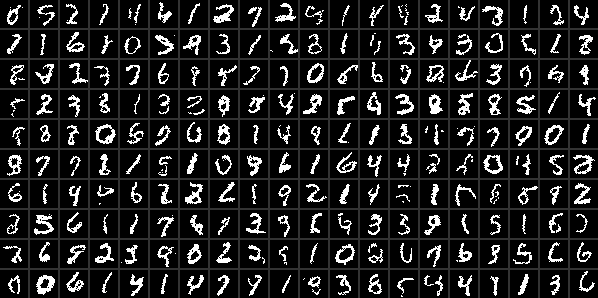

In [28]:
vec2imgs(sample(wave_net_dil_loc, 200); nrows=10)

In [29]:
logpdf(wave_net_dil_loc, mnist_binary_test_loader)

-84.4277f0

In [30]:
begin
    Random.seed!(123)
    wave_net_dil_loc_skip_fwd = WaveNet(28^2, n_layers, ks, nc; forward_mode=:skip, add_loc=true, dilation=true) |> device
    losses_dil_loc__skipfwd_wn, _ = fit!(wave_net_dil_loc_skip_fwd, mnist_binary_loader, Adam(), 10; verbose=true, every_epoch=2, learning_rate_decay=false, validation_data_loader=nothing)
end

[ Info: Epoch 1; Loss = 89.2276
Progress:  20%|████████▎                                |  ETA: 0:02:22[ Info: Epoch 3; Loss = 89.8684
Progress:  40%|████████████████▍                        |  ETA: 0:01:38[ Info: Epoch 5; Loss = 84.524
Progress:  60%|████████████████████████▋                |  ETA: 0:01:03[ Info: Epoch 7; Loss = 81.268
Progress:  80%|████████████████████████████████▊        |  ETA: 0:00:31[ Info: Epoch 9; Loss = 86.0289
Progress: 100%|█████████████████████████████████████████| Time: 0:02:33


(Any[584.50995f0, 529.0428f0, 500.316f0, 469.647f0, 434.79187f0, 402.13852f0, 369.44937f0, 344.60458f0, 319.022f0, 326.64648f0  …  83.03194f0, 87.74072f0, 85.00949f0, 85.13753f0, 88.96877f0, 85.26654f0, 84.45552f0, 87.6568f0, 88.77312f0, 85.38072f0], WaveNet{CausalConv1D{Conv{1, 2, typeof(identity), Array{Float32, 3}, Vector{Float32}}}, Chain{NTuple{9, ResWaveNetBlock{CausalConv1D{Conv{1, 2, typeof(identity), Array{Float32, 3}, Vector{Float32}}}, Conv{1, 2, typeof(identity), Array{Float32, 3}, Vector{Float32}}}}}, Chain{Tuple{CausalConv1D{Conv{1, 2, typeof(relu), Array{Float32, 3}, Vector{Float32}}}, CausalConv1D{Conv{1, 2, typeof(identity), Array{Float32, 3}, Vector{Float32}}}}}}(784, CausalConv1D{Conv{1, 2, typeof(identity), Array{Float32, 3}, Vector{Float32}}}(Conv((2,), 2 => 32), false), Chain(ResWaveNetBlock{CausalConv1D{Conv{1, 2, typeof(identity), Array{Float32, 3}, Vector{Float32}}}, Conv{1, 2, typeof(identity), Array{Float32, 3}, Vector{Float32}}}(CausalConv1D{Conv{1, 2, typeo

In [31]:
logpdf(wave_net_dil_loc_skip_fwd, mnist_binary_test_loader)

-84.98005f0

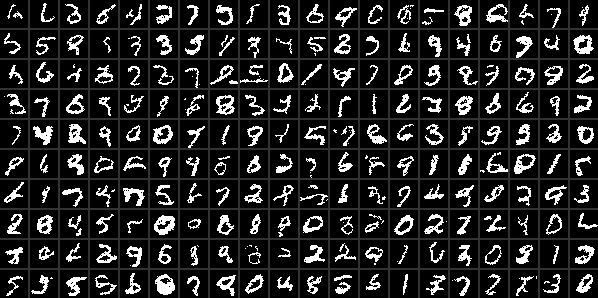

In [32]:
vec2imgs(sample(wave_net_dil_loc_skip_fwd, 200); nrows=10)

In [33]:

"""
    test_autoregressive_property_comprehensive(model; input_shape=(T, C, N), time_dim=1)

Vigorously tests the autoregressive property across EVERY time step in a sequence.
Returns `true` if the model is perfectly causal across all points, or `false` if a leak occurs.
"""
function test_autoregressive_property_comprehensive(model; input_shape=(10, 1, 1), time_dim=1)
    # 1. Generate a dummy input tensor with random floats
    x = rand(Float32, input_shape...)
    T = size(x, time_dim) # Number of time steps

    # 2. Iterate through every single output time step 't_out'
    for t_out in 1:T

        # 3. Compute gradients of the output at step t_out with respect to ALL inputs
        grads = Flux.gradient(x) do input_tensor
            out = model(input_tensor)

            # Isolate the output slice at this specific time step
            out_at_t = selectdim(out, time_dim, t_out)

            # Sum to scalar objective for AD tracking
            return sum(out_at_t)
        end

        # Extract the gradient array back from the gradients tuple
        grad_x = grads[1]

        # 4. Check every input time step 't_in' against our current 't_out'
        for t_in in 1:T
            grad_slice = selectdim(grad_x, time_dim, t_in)
            max_grad = maximum(abs, grad_slice)

            # CRITICAL PROPERTY: If t_in occurs AFTER t_out, the gradient MUST be 0.
            if t_in > t_out
                if max_grad > 1e-7
                    @error "🚨 Future Leakage Found!" t_out t_in max_grad
                    return false
                end
            end
        end
    end

    println("✅ Perfect Causality: Verified across all time steps.")
    return true
end


test_autoregressive_property_comprehensive (generic function with 1 method)

In [34]:
test_autoregressive_property_comprehensive(wave_net_dil_loc |> cpu; input_shape=(28^2, 1, 1))

✅ Perfect Causality: Verified across all time steps.


true

In [ ]:
train_loader, test_loader, valid_loader = load_mnist_data(batch_size; dtype=Bool, tensor_shape=(28*28, 1, :))

(DataLoader(data::Tuple{SubArray{Bool, 3, BitArray{3}, Tuple{Base.Slice{Base.OneTo{Int64}}, Base.Slice{Base.OneTo{Int64}}, UnitRange{Int64}}, true}, Vector{Int64}}, shuffle=true, batchsize=50), DataLoader(data::Tuple{BitArray{3}, Vector{Int64}}, shuffle=true, batchsize=50), DataLoader(data::Tuple{BitArray{3}, Vector{Int64}}, shuffle=true, batchsize=50))

In [36]:
begin
    Random.seed!(123)
    wave_net_dil_loc_new_data = WaveNet(28^2, n_layers, ks, nc; add_loc=true, dilation=true) |> device
    losses_dil_loc_wn_new_data, _ = fit!(wave_net_dil_loc_new_data, train_loader, Adam(), 10; verbose=true, every_epoch=2, learning_rate_decay=false, validation_data_loader=nothing)
end

[ Info: Epoch 1; Loss = 93.4504
Progress:  20%|████████▎                                |  ETA: 0:02:20[ Info: Epoch 3; Loss = 90.8708
Progress:  40%|████████████████▍                        |  ETA: 0:01:45[ Info: Epoch 5; Loss = 85.4498
Progress:  60%|████████████████████████▋                |  ETA: 0:01:10[ Info: Epoch 7; Loss = 86.5832
Progress:  80%|████████████████████████████████▊        |  ETA: 0:00:35[ Info: Epoch 9; Loss = 85.8907
Progress: 100%|█████████████████████████████████████████| Time: 0:02:53


(Any[587.16296f0, 470.2057f0, 388.38895f0, 345.8471f0, 331.59085f0, 315.67722f0, 300.99194f0, 302.75266f0, 281.49155f0, 262.83908f0  …  86.38315f0, 89.033104f0, 80.58275f0, 85.96865f0, 86.29463f0, 81.791595f0, 81.7262f0, 90.565094f0, 88.073135f0, 86.22132f0], WaveNet{CausalConv1D{Conv{1, 2, typeof(identity), Array{Float32, 3}, Vector{Float32}}}, Chain{NTuple{9, ResWaveNetBlock{CausalConv1D{Conv{1, 2, typeof(identity), Array{Float32, 3}, Vector{Float32}}}, Conv{1, 2, typeof(identity), Array{Float32, 3}, Vector{Float32}}}}}, CausalConv1D{Conv{1, 2, typeof(identity), Array{Float32, 3}, Vector{Float32}}}}(784, CausalConv1D{Conv{1, 2, typeof(identity), Array{Float32, 3}, Vector{Float32}}}(Conv((2,), 2 => 32), false), Chain(ResWaveNetBlock{CausalConv1D{Conv{1, 2, typeof(identity), Array{Float32, 3}, Vector{Float32}}}, Conv{1, 2, typeof(identity), Array{Float32, 3}, Vector{Float32}}}(CausalConv1D{Conv{1, 2, typeof(identity), Array{Float32, 3}, Vector{Float32}}}(Conv((2,), 32 => 64), false), C

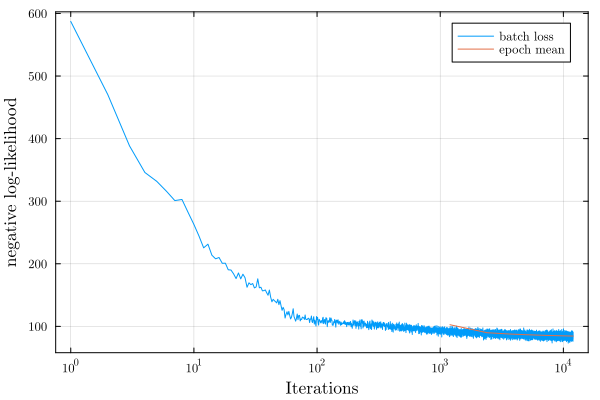

In [37]:
plot_loss(losses_dil_loc_wn_new_data, length(train_loader))

In [38]:
logpdf(wave_net_dil_loc_new_data, mnist_binary_test_loader), logpdf(wave_net_dil_loc_new_data, test_loader)

(-83.97891f0, -83.796776f0)

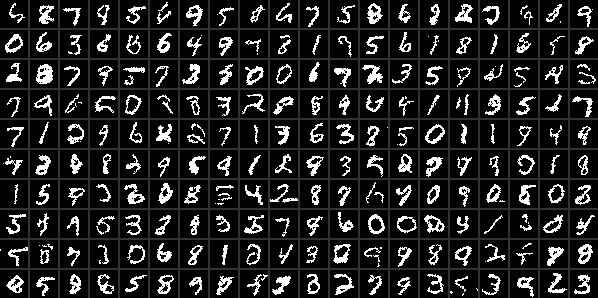

In [39]:
vec2imgs(sample(wave_net_dil_loc_new_data, 200), nrows=10)

In [40]:
begin

    struct ConResWaveNetBlock{T<:ResWaveNetBlock}
        res_block::T
        con_f::Dense
        con_g::Dense
    end

    Flux.@layer ConResWaveNetBlock trainable = (res_block, con_f, con_g)


    function ConResWaveNetBlock(kernel_size::Int=2, dilation::Int=1, ch::Int=32, h_size::Int=5)
        # causal_conv = CausalConv1D(kernel_size, ch => 2 * ch, identity; res_con=false, dilation=dilation, bias=true)
        # res_conv = Conv((1,), ch => ch, identity)
        # ResWaveNetBlock(causal_conv, res_conv, with_cond)
        res_block = ResWaveNetBlock(kernel_size, dilation, ch)
        con_f = Dense(h_size=>ch; bias=false)
        con_g = Dense(h_size=>ch; bias=false)
        ConResWaveNetBlock(res_block, con_f, con_g)
    end


    function (m::ConResWaveNetBlock)((xs, hs))
        output = m.res_block.causal_con(xs)
        out_f, out_g = Flux.chunk(output, 2, dims=2)
        hf = m.con_f(hs)
        hg = m.con_g(hs)
        output = tanh.(out_f .+ reshape(hf, 1, size(hf)...)) .* σ(out_g .+ reshape(hg, 1, size(hg)...))
        output = m.res_block.res_con(output)
        return xs + output, output
    end
end

In [41]:
begin

    struct ConWaveNet{T<:CausalConv1D,Y<:Chain,K<:Union{Chain,CausalConv1D}}
        d::Int ## number of input; or input dimension
        num_classes::Int
        input_layer::T
        res_blocks::Y
        output_layer::K
        # emb::L
        add_loc::Bool
        forward_mode::Symbol ## forward mode: :chain or :skip
    end

    Flux.@layer ConWaveNet trainable = (input_layer, res_blocks, output_layer)

    function ConWaveNet(d::Int=28^2, num_layers=5, kernel_size::Int=2, nc::Int=32, num_classes::Int=10; forward_mode=:chain, add_loc=true, dilation=true, act=relu, init=Flux.glorot_uniform)
        input_layer = CausalConv1D(kernel_size, (add_loc ? 2 : 1) => nc, identity; res_con=false, dilation=1, bias=true)   ## causal mask A
        res_blocks = []
        cap_l = floor(Int, log(kernel_size, 512))
        dils = [2^(l-1) for l in 1:(cap_l+1)]
        for l in 1:num_layers
            dil = dilation ? dils[((l-1)%(length(dils))+1)] : 1 ## exponentially expanding dilation and cycle back 1,2,…,512,1,2,3...
            dil = min(dil, 512)
            push!(res_blocks, ConResWaveNetBlock(kernel_size, dil, nc, num_classes))
        end
        if forward_mode == :chain
            output_layer = CausalConv1D(1, nc => 1)
        else
            out1 = CausalConv1D(1, nc => nc, act)
            out2 = CausalConv1D(1, nc => 1, identity)
            output_layer = Chain(out1, out2)
        end
        # emb = Embedding(num_classes=>emb_size)
        ConWaveNet(d, num_classes, input_layer, Chain(res_blocks...), output_layer, add_loc, forward_mode)
    end


    function (m::ConWaveNet)((xs, ys))
        if m.add_loc
            loc = Flux.ignore_derivatives() do
                location_feature(xs)
            end
            xs = cat(xs, loc, dims=2)
        end
        xs = Flux.pad_zeros(xs, (1, 0), dims=1)[1:(end-1), :, :]
        outs = m.input_layer(xs)
        # hs = m.emb(ys .+ 1) ## embedding of the labels
        hs = Flux.onehotbatch(ys, 0:(m.num_classes-1))
        out1, out2 = m.res_blocks[1]((outs, hs)) ## send both xs and the ys embeddings
        total_skip = out2
        for layer in m.res_blocks[2:end]
            out1, out2 = layer((out1, hs)) ## the condition embeddings are reinforced at this layer
            total_skip += out2
        end

        if m.forward_mode == :chain
            output = m.output_layer(out1)
        else
            total_skip = relu(total_skip)
            output = m.output_layer(total_skip)
        end

        return output
    end



end

In [42]:
function fit!(model::ConWaveNet, data_loader, optim=Adam(), max_epochs=10; verbose=true, every_epoch=10)
    opt = Flux.setup(optim, model)
    losses = []
    @showprogress for epoch in 1:max_epochs
        for xys in data_loader
            xys = xys |> device
            li, gs = Flux.withgradient(model) do m
                -logpdf(m, xys)
            end
            Flux.update!(opt, model, gs[1])
            push!(losses, li)
        end
        if verbose && (epoch % every_epoch) == 1
            @info "Epoch $(epoch); Loss = $(round(losses[end]; digits=4))"
        end
    end

    return losses
end

fit! (generic function with 6 methods)

In [43]:
function logpdf(model::ConWaveNet, (xs, ys)::Tuple{T, Y}; reduction=mean) where {T <: AbstractArray, Y <: AbstractArray}
    xs_preds = model((xs, ys))
    logL = -Flux.logitbinarycrossentropy(xs_preds[:, 1, :], xs[:, 1, :]; agg=identity)
    logL = sum(logL, dims=1)
    logL |> reduction
end


function logpdf(model::ConWaveNet, data_loader::Flux.DataLoader; reduction=mean)
    logLiks = []
    for (xs, ys) in data_loader
        xs, ys = (xs, ys) |> device
        logL = logpdf(model, (xs, ys); reduction=identity)[:]
        append!(logLiks, logL)
    end
    return logLiks |> reduction
end

logpdf (generic function with 4 methods)

In [ ]:
function sample(model::ConWaveNet, ys, n=1; samples_only = true)
    xs = Array{Bool}(undef, model.d, 1, n) |> device
    probs = similar(xs)
    if ys isa Number
        ys = repeat([ys], n)
    end
    for d in 1:model.d
        ps = σ(model((xs, ys))[d, :, :])
        xs[d, 1, :] = rand_like(ps)[:] .< ps[:]
        probs[d, 1, :] = ps
    end
    if samples_only
        return xs[:, 1, :]
    else
        return xs[:, 1, :], probs[:, 1, :]
    end
end

sample (generic function with 4 methods)

In [45]:
begin
    Random.seed!(123)

    # ConWaveNet()
    con_wnet = ConWaveNet(28^2, n_layers, 2, nc, 10;  add_loc=true, dilation=true, act=relu, init=Flux.glorot_uniform) |> device
    losses_con_wnet = fit!(con_wnet, train_loader, Adam(), 10; verbose=true, every_epoch=2)

end;

[ Info: Epoch 1; Loss = 89.2965
Progress:  20%|████████▎                                |  ETA: 0:05:55[ Info: Epoch 3; Loss = 79.6713
Progress:  40%|████████████████▍                        |  ETA: 0:03:30[ Info: Epoch 5; Loss = 77.8311
Progress:  60%|████████████████████████▋                |  ETA: 0:02:08[ Info: Epoch 7; Loss = 77.8896
Progress:  80%|████████████████████████████████▊        |  ETA: 0:01:01[ Info: Epoch 9; Loss = 82.5664
Progress: 100%|█████████████████████████████████████████| Time: 0:04:54


In [46]:
begin
    Random.seed!(123)

    # ConWaveNet()
    con_wnet_skip = ConWaveNet(28^2, n_layers, 2, nc, 10; forward_mode=:skip, add_loc=true, dilation=true, act=relu, init=Flux.glorot_uniform) |> device
    losses_con_wnet_skip = fit!(con_wnet_skip, train_loader, Adam(), 10; verbose=true, every_epoch=2)

end;

[ Info: Epoch 1; Loss = 91.5805
Progress:  20%|████████▎                                |  ETA: 0:03:59[ Info: Epoch 3; Loss = 85.0967
Progress:  40%|████████████████▍                        |  ETA: 0:02:49[ Info: Epoch 5; Loss = 84.6447
Progress:  60%|████████████████████████▋                |  ETA: 0:01:51[ Info: Epoch 7; Loss = 78.8638
Progress:  80%|████████████████████████████████▊        |  ETA: 0:00:55[ Info: Epoch 9; Loss = 82.5103
Progress: 100%|█████████████████████████████████████████| Time: 0:04:31


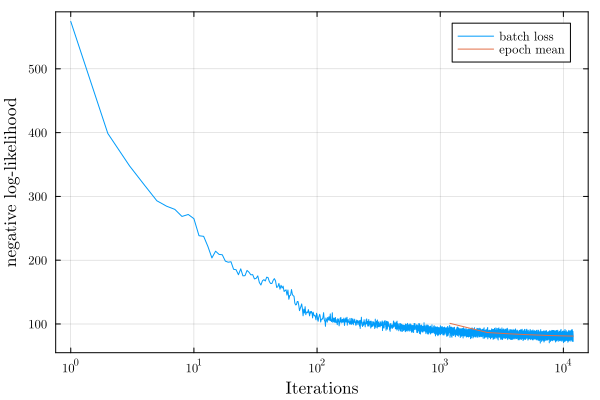

In [47]:
plot_loss(losses_con_wnet, length(train_loader))

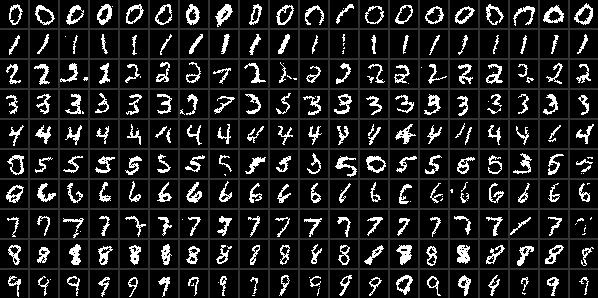

In [48]:
vec2imgs(sample(con_wnet, repeat(0:9, inner=20), 200), nrows=10)

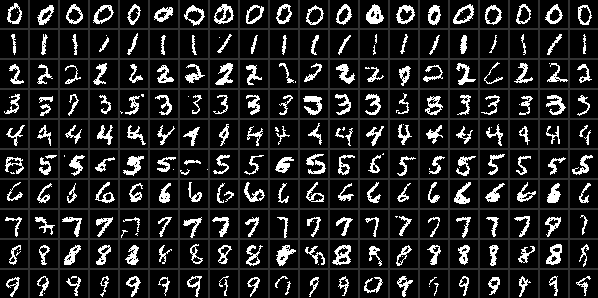

In [49]:
vec2imgs(sample(con_wnet_skip, repeat(0:9, inner=20), 200), nrows=10)

In [50]:
logpdf(con_wnet, test_loader)

-80.50216f0

In [51]:
logpdf(con_wnet_skip, test_loader)

-80.66187f0

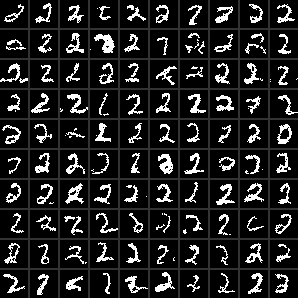

In [52]:
vec2imgs(sample(con_wnet, 2, 100), nrows=10)

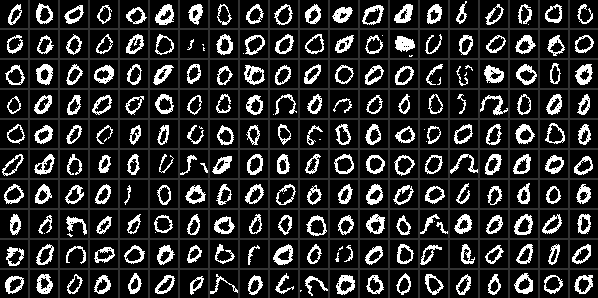

In [53]:
vec2imgs(sample(con_wnet_skip, 0, 200), nrows=10)

In [54]:
# con_wnet(xs)
xs, ys = test_loader |> first
logliks = []
for y in 0:9
# y = 0
    xys = (xs, repeat([y], size(xs)[end])) |> device
    ll = logpdf(con_wnet, xys; reduction = identity)

    push!(logliks, ll)
end

In [55]:
logliks = vcat(logliks...)
postp = exp.(logliks .- logsumexp(logliks, dims=1))

10×50 CuArray{Float32, 2, CUDACore.DeviceMemory}:
 4.79f-12     9.11049f-9   7.15667f-13  …  4.24584f-5   1.46714f-9
 8.4852f-17   4.83886f-15  1.04515f-19     1.27853f-18  6.0145f-18
 6.61089f-7   2.46265f-7   1.32738f-5      1.21362f-7   1.0
 3.2825f-7    6.34266f-7   5.29678f-7      2.29639f-7   2.56388f-12
 7.27254f-13  1.74408f-14  1.81581f-10     7.92868f-18  2.621f-12
 4.39253f-12  2.5271f-7    1.17941f-7   …  0.999825     2.46163f-11
 4.88327f-14  1.65103f-8   1.30178f-10     4.05748f-8   3.45153f-15
 1.06695f-8   2.86499f-18  2.80356f-11     3.08714f-10  3.50801f-13
 1.0          1.0          0.999985        0.000131073  8.79212f-13
 6.70061f-7   7.29483f-9   6.5364f-11      3.70695f-11  3.65538f-13

In [56]:
mean(argmax.(eachcol(postp |> cpu)) .== ys .+1)

0.96

In [57]:
function predict_y(model::ConWaveNet, xs::T) where {T<:AbstractArray}
    logliks = []
    for y in 0:(model.num_classes-1)
        xys = (xs, repeat([y], size(xs)[end])) |> device
        ll = logpdf(con_wnet, xys; reduction=identity)
        push!(logliks, ll)
    end
    logliks = vcat(logliks...)
    postp = exp.(logliks .- logsumexp(logliks, dims=1))
end

predict_y (generic function with 1 method)

In [58]:
function predict_y(model::ConWaveNet, data_loader)
    post_prob = []
    targets = []
    for (xs, ys) in data_loader
        postp=predict_y(model, xs)
        push!(post_prob, postp)
        push!(targets, ys)
    end
    return hcat(post_prob...), targets
end

predict_y (generic function with 2 methods)

In [59]:
pps,targets = predict_y(con_wnet, test_loader)
mean(argmax.(eachcol(pps |> cpu)) .== vcat(targets...).+1)

0.9787

In [60]:
pps,targets = predict_y(con_wnet_skip, test_loader)
mean(argmax.(eachcol(pps |> cpu)) .== vcat(targets...).+1)

0.9787